# Cohort Analysis of Contributors - Visualization

This notebook prototypes the Cohort Analysis graph for 8Knot, see issue https://github.com/chaoss/8Knot/issues/1110

A cohort is a group of contributors whose first action in the selected repos happened in the same month. The graph shows how many of each cohort are still active 1, 2, 3 or more months later.

Description of Graph:

* X-axis: Months after the first action (0 is the cohort month)
* Y-axis: Cohort (month of first action)
* Color and number in each box: % of the cohort that was active in that month

The notebook does all the preprocessing down to the visualization, so it can be tested and checked before implementing it on 8Knot.

It uses the same data as 8Knot's contributors page (the `explorer_contributor_actions` view, the query in `8Knot/queries/contributors_query.py`), so the result can move into 8Knot without a new query.

### Importing Libraries

In [1]:
import sys
import subprocess
import pandas as pd
import sqlalchemy as salc
import json
from pathlib import Path
import datetime as dt
import plotly.graph_objects as go

## Installing Dependencies - Package Management

* This particular implementation uses requirements.txt to install the dependencies

In [2]:
# Package management - Installing requirements.txt
_repo_root = Path.cwd().parent if Path.cwd().name == "wg-data-science" else Path.cwd()
_req_notebook = Path(__file__).parent / "requirements.txt" if "__file__" in dir() else _repo_root / "wg-data-science" / "requirements.txt"
if not _req_notebook.exists():
    _req_notebook = _repo_root / "requirements.txt"

if _req_notebook.exists():
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(_req_notebook)], check=True)
    print("Installed notebook deps from", _req_notebook)
else:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "pandas", "sqlalchemy", "plotly", "psycopg2-binary"],
        check=True,
    )
    print("Installed minimal deps (requirements.txt not found)")

Installed minimal deps (requirements.txt not found)


### Loading Credentials - .json

In [3]:
# augur_creds.json lives in the same folder as this notebook (8knot/).
# If Jupyter's working directory is the folder above, fall back to 8knot/augur_creds.json.
_cred_path = Path("augur_creds.json")
if not _cred_path.is_file():
    _cred_path = Path("8knot") / "augur_creds.json"
if not _cred_path.is_file():
    raise FileNotFoundError(
        "augur_creds.json should sit next to cohort_analysis.ipynb. "
        f"Not found from cwd: {Path.cwd().resolve()}"
    )
with open(_cred_path) as config_file:
    config = json.load(config_file)

### DB connection

In [4]:
database_connection_string = "postgresql+psycopg2://{}:{}@{}:{}/{}".format(
    config["user"], config["password"], config["host"], config["port"], config["database"]
)
# Schema name. Augur uses augur_data. The CollectOSS sample database uses data.
# Put "schema" in augur_creds.json to change it, otherwise augur_data is used.
dbschema = config.get("schema", "augur_data")
engine = salc.create_engine(
    database_connection_string,
    connect_args={"options": "-csearch_path={}".format(dbschema)},
)

### Queries

Get repo_ids and repo_names from augur data

In [5]:
# Use a list of repo urls, for example ["https://github.com/chaoss/augur"], or [] to use every repo in the database
repo_urls = []

if repo_urls:
    url_query = str(repo_urls)[1:-1]
    repo_filter_sql = f"WHERE r.repo_git IN ({url_query})"
else:
    repo_filter_sql = ""

repo_query = salc.sql.text(
    f"""
    SELECT DISTINCT r.repo_id, r.repo_name
    FROM repo r
    {repo_filter_sql}
    """
)
with engine.connect() as conn:
    t = conn.execute(repo_query)
    results = t.all()
repo_ids = [row[0] for row in results]
repo_names = [row[1] for row in results]
print(repo_ids)
print(repo_names)

[25452, 24441, 1, 25430, 25445, 25450, 24442]
['whitepaper', 'operate-first-twitter', 'augur', 'update-test', 'grimoirelab-perceval-opnfv', 'grimoirelab-hatstall', 'blueprint']


Query for contributor actions

This is the same query 8Knot uses for its contributors page (`contributors_query`). Each row is one action by one contributor: cntrb_id (the person), created_at (when) and action (issue opened, PR merged, comment and so on).

With this info the contributor-action table is built.

In [6]:
repo_statement = str(repo_ids)[1:-1]

query = salc.sql.text(f"""
    SELECT
        ca.repo_id,
        ca.repo_name,
        left(ca.cntrb_id::text, 15) AS cntrb_id,
        timezone('utc', ca.created_at) AS created_at,
        ca.login,
        ca.action
    FROM explorer_contributor_actions ca
    WHERE ca.repo_id IN ({repo_statement})
        AND timezone('utc', ca.created_at) < now()
""")
df = pd.read_sql(query, con=engine)

# same cleaning 8Knot does after the query
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df = df[df["cntrb_id"].notna()]
df["cntrb_id"] = df["cntrb_id"].astype(str)

### Optional filters (date range, months shown, bots)

There is also the option of adding filters into the graph

The options are:

* Only consider actions from START_DATE to END_DATE
* How many months after the first action to show
* Leave out accounts whose login contains certain text (for example "bot")

Default for the bot filter is ["bot"]. Use an empty list [] to keep everyone.

In [7]:
START_DATE = "2023-01-01"   # first month of the cohorts
END_DATE = "2026-04-30"     # last month of data used
MAX_MONTHS = 12             # months after the first action to show
EXCLUDE_LOGIN_TEXT = ["bot"]  # logins containing this text are left out; [] keeps everyone

for text_part in EXCLUDE_LOGIN_TEXT:
    df = df[~df["login"].fillna("").str.lower().str.contains(text_part.lower(), regex=False)]

### Data Processing

In [8]:
df.head()

,repo_id,repo_name,cntrb_id,created_at,login,action
0,1,augur,010e02d3-aa00-0,2026-04-22 19:06:05+00:00,mn-ram,pull_request_closed
1,1,augur,010e02d3-aa00-0,2026-04-22 19:06:05+00:00,mn-ram,pull_request_closed
2,1,augur,010e02d3-aa00-0,2026-04-22 19:06:04+00:00,mn-ram,pull_request_closed
3,1,augur,010e02d3-aa00-0,2026-04-22 19:06:04+00:00,mn-ram,pull_request_closed
4,1,augur,010e02d3-aa00-0,2026-04-22 19:06:03+00:00,mn-ram,pull_request_closed


Here is where we build the cohorts.

* The first action of every contributor is found using ALL history in the selected repos, not only the date range.
* A contributor whose first action is before START_DATE is marked "started earlier" and left out, so an old contributor cannot look like a new one.
* The cohort is the month of the first action.
* For every later month we check if that contributor did anything.
* df_counts holds the number of active contributors, df_plot holds the percentage of the cohort.

In [9]:
df["month"] = df["created_at"].dt.tz_localize(None).dt.to_period("M")

start = pd.Timestamp(START_DATE).to_period("M")
end = pd.Timestamp(END_DATE).to_period("M")

# First action of every contributor, using all history
first_month = df.groupby("cntrb_id")["month"].min().rename("cohort")
print("Contributors who started before the start date (left out):", int((first_month < start).sum()))

# One row per contributor per active month, inside the date range only
active = df[(df["month"] >= start) & (df["month"] <= end)][["cntrb_id", "month"]].drop_duplicates()
active = active.merge(first_month, on="cntrb_id")
active = active[active["cohort"] >= start]

# Months after the cohort month
active["months_after"] = (active["month"].dt.year - active["cohort"].dt.year) * 12 + (
    active["month"].dt.month - active["cohort"].dt.month
)
active = active[active["months_after"] <= MAX_MONTHS]

df_counts = (
    active.groupby(["cohort", "months_after"])["cntrb_id"]
    .nunique()
    .unstack("months_after")
    .reindex(columns=range(MAX_MONTHS + 1))
    .fillna(0)
    .astype(int)
)

# Percent of the cohort that is active in each month
cohort_size = df_counts[0]
df_plot = (df_counts.divide(cohort_size, axis=0) * 100).round(1)

# Months that have not happened yet (after END_DATE) are left empty, not shown as 0
for cohort in df_plot.index:
    months_possible = (end - cohort).n
    df_plot.loc[cohort, [m for m in df_plot.columns if m > months_possible]] = float("nan")

df_plot.index = df_plot.index.astype(str)
cohort_size.index = cohort_size.index.astype(str)
df_plot

Contributors who started before the start date (left out): 337


months_after,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2023-01,100.0,75.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-02,100.0,25.0,25.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-03,100.0,33.3,0.0,33.3,0.0,0.0,33.3,33.3,0.0,0.0,0.0,0.0,0.0
2023-04,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-05,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-06,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-08,100.0,9.1,9.1,9.1,0.0,9.1,9.1,9.1,9.1,9.1,9.1,0.0,0.0
2023-09,100.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-10,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Plots

The chart uses the filtered data from above.

## Contributor Retention by Cohort

Each row is a cohort. Each box shows the % of that cohort that was active again N months after their first action. Empty boxes are months that have not happened yet.

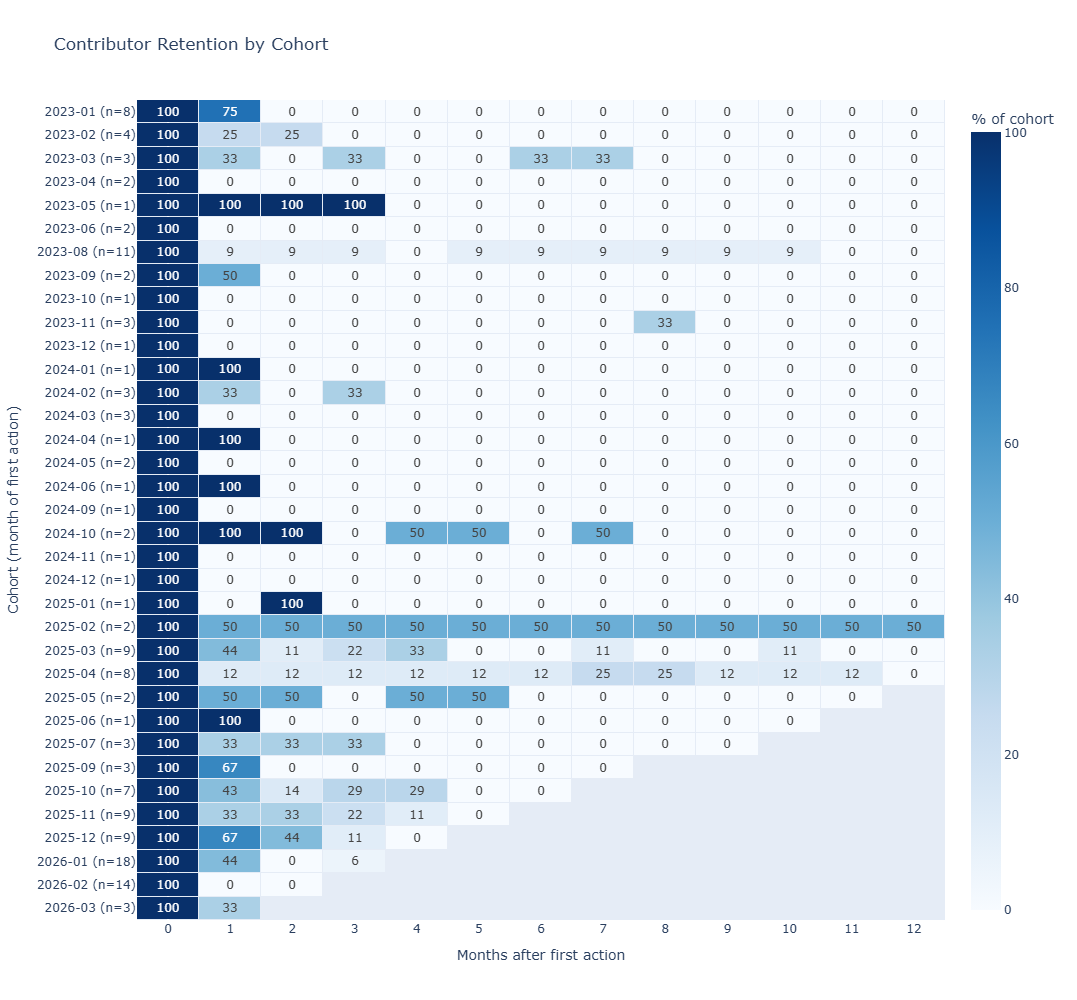

In [10]:
# One label per cohort, and a chart tall enough to show every row
row_labels = [f"{c} (n={cohort_size[c]})" for c in df_plot.index]

fig = go.Figure(
    go.Heatmap(
        z=df_plot.values,
        x=[int(c) for c in df_plot.columns],
        y=row_labels,
        xgap=1,
        ygap=1,
        zmin=0,
        zmax=100,
        colorscale="Blues",
        colorbar=dict(title="% of cohort"),
        text=[["" if pd.isna(v) else f"{v:.0f}" for v in row] for row in df_plot.values],
        texttemplate="%{text}",
        hovertemplate="Cohort %{y}<br>Months after first action: %{x}<br>Active: %{z:.1f}%<extra></extra>",
    )
)
fig.update_layout(
    title="Contributor Retention by Cohort",
    xaxis_title="Months after first action",
    yaxis_title="Cohort (month of first action)",
    xaxis=dict(dtick=1, showgrid=False),
    yaxis=dict(type="category", autorange="reversed", tickmode="array", tickvals=row_labels, showgrid=False),
    height=max(400, 24 * len(row_labels) + 160),
    font=dict(size=12),
)
fig.show()

### How to read it

1. Each row is a group of people who made their first action in the same month, and n is the size of the group.
2. Each column is how many months later we check.
3. A box shows the share of that group that did something again in that month.
4. A row that fades quickly means people tried the project once and left. A row that stays dark means people stayed.

Limits to remember

1. Cohorts near the end of the date range have fewer months to show, so their boxes at the right stay empty.
2. Only people the database could link to a contributor id are counted.
3. A person who started before the start date is left out.
4. Bots are found by text in the login. A bot without that text would still be counted.